# Лабораторная работа №4
## Применение рекуррентных нейронных сетей для анализа временных рядов

**Вариант 0 — ежедневные продажи розничного магазина.**

Цель работы — исследовать временной ряд продаж, подготовить данные, выполнить статистический анализ, построить базовые модели и рекуррентные нейронные сети LSTM и GRU, а также сравнить качество прогнозирования.

Основной протокол:
- частота временной сетки — 1 минута;
- длина входного окна — 1440 минут (24 часа);
- горизонт прогнозирования — 2880 минут (48 часов);
- разделение данных — хронологическое Train / Validation / Test;
- масштабирование — только по обучающей выборке;
- метрики — MAE, RMSE, MASE и Pinball Loss;
- дополнительная проверка — walk-forward backtesting
  (expanding vs rolling, длина rolling-окна — 90 суток, чтобы
  покрыть дневные лаги моделей ETS и Gradient Boosting).

## 1. Импорт библиотек и настройка воспроизводимости

Используются NumPy и pandas для работы с данными, Matplotlib для визуализации, statsmodels для статистического анализа и базовых моделей, scikit-learn для градиентного бустинга и PyTorch для реализации LSTM и GRU.

Для воспроизводимости фиксируются генераторы случайных чисел Python, NumPy и PyTorch. Если доступен GPU, обучение идёт на нём — это существенно ускоряет LSTM/GRU и не меняет результаты по существу.

In [104]:
import os
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.ensemble import HistGradientBoostingRegressor

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

SEED = 42
VARIANT = 0

GRID = "1min"
WINDOW = 1440
HORIZON = 2880
SEASONAL_PERIOD = 1440
LEADS = [1, 60, 360, 1440, 2880]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Используемое устройство: {DEVICE}")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()

Используемое устройство: cuda


## 2. Формирование исходного временного ряда

Для варианта 0 рассматриваются ежедневные продажи розничного магазина.

Если собственный датасет не предоставлен, используется синтетический учебный ряд. Он включает:
- базовый уровень продаж;
- долгосрочный тренд;
- недельную сезонность;
- годовую сезонность;
- случайный шум;
- отдельные аномальные наблюдения.

Синтетические данные позволяют продемонстрировать полный процесс анализа. Они не являются реальными данными магазина, поэтому выводы относятся только к сформированному учебному ряду.

In [105]:
def generate_sales_data(n_days=1825, seed=SEED):
    rng = np.random.default_rng(seed)
    t = np.arange(n_days)

    base = 500
    trend = 0.08 * t
    weekly = 45 * np.sin(2 * np.pi * t / 7) + 20 * np.cos(2 * np.pi * t / 7)
    yearly = 65 * np.sin(2 * np.pi * t / 365.25)
    noise = rng.normal(0, 25, n_days)

    anomalies = np.zeros(n_days)
    anomaly_indices = rng.choice(n_days, size=15, replace=False)
    anomalies[anomaly_indices] = rng.normal(0, 100, len(anomaly_indices))

    sales = base + trend + weekly + yearly + noise + anomalies
    sales = np.maximum(sales, 1)

    dates = pd.date_range(start="2021-01-01", periods=n_days, freq="D")
    return pd.Series(sales, index=dates, name="sales")


daily_series = generate_sales_data()

print("Количество наблюдений:", len(daily_series))
print("Начало периода:", daily_series.index.min())
print("Конец периода:", daily_series.index.max())
display(daily_series.head())
display(daily_series.describe())

Количество наблюдений: 1825
Начало периода: 2021-01-01 00:00:00
Конец периода: 2025-12-30 00:00:00


,sales
2021-01-01,527.617927
2021-01-02,522.850712
2021-01-03,560.578491
2021-01-04,528.612493
2021-01-05,418.469076


,sales
count,1825.000000
mean,571.665387
std,70.985408
min,365.233273
25%,523.704405
50%,571.881222
75%,621.209330
max,782.392472


### 2.1. Первичная визуализация

Построим график ежедневных продаж.

По графику оцениваются:
- наличие долгосрочного тренда;
- повторяющиеся колебания;
- возможные аномальные значения;
- изменение уровня и амплитуды ряда.

Визуальный анализ дополняет статистические тесты и помогает сформулировать гипотезы о структуре временного ряда.

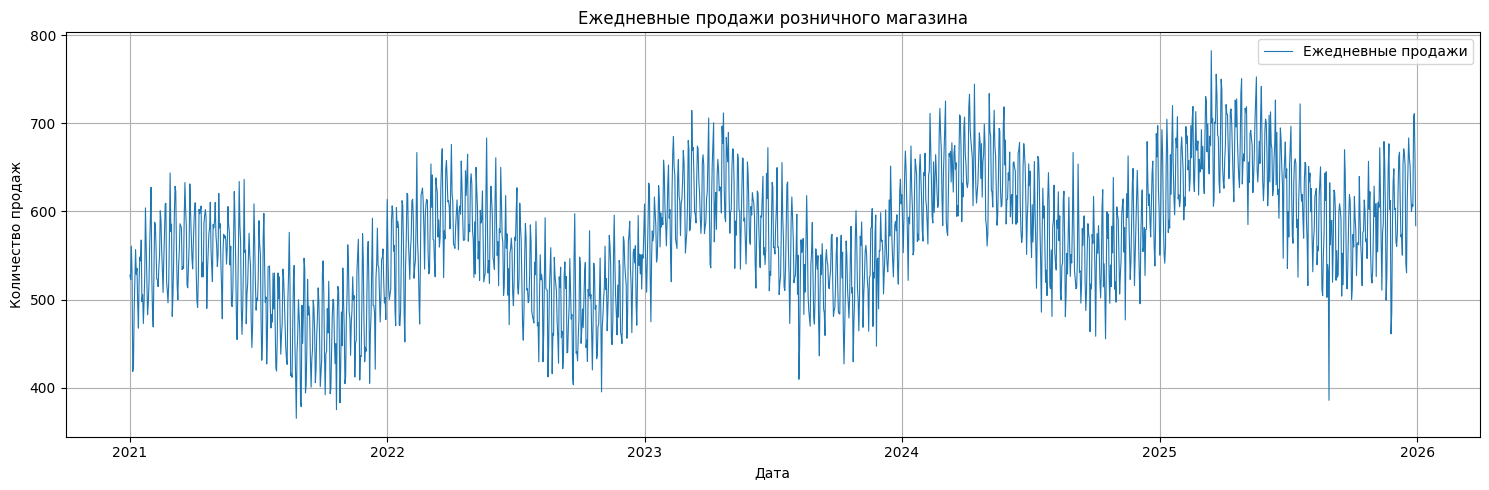

In [106]:
plt.figure(figsize=(15, 5))
plt.plot(daily_series.index, daily_series.values, linewidth=0.8, label="Ежедневные продажи")
plt.title("Ежедневные продажи розничного магазина")
plt.xlabel("Дата")
plt.ylabel("Количество продаж")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Предварительный вывод.**

График строится синтетически с заданной структурой: линейный тренд, недельная и годовая сезонности, шум и 15 аномальных точек (σ≈100). Поэтому визуально ряд должен демонстрировать:

- медленный рост среднего уровня (тренд);
- регулярные колебания недельной амплитуды;
- более широкие годовые волны;
- отдельные выбросы, заметно отклоняющиеся от локального среднего.

Точные наблюдения по фактическому графику приведены в интерпретации после построения; количественные характеристики проверяются в разделах 4–6 статистическими тестами.

## 3. Обработка пропусков и приведение к минутной сетке

Сначала создадим искусственные пропуски в дневном ряду, чтобы продемонстрировать процедуру обработки.

Для учебного примера используется линейная интерполяция по времени. Она восстанавливает пропущенные значения по соседним известным наблюдениям.

Затем дневной ряд переводится на регулярную минутную сетку. При этом минутные значения являются интерполированными, а не фактически измеренными продажами.

Это ограничение важно учитывать при оценке качества нейронной сети: модель анализирует искусственно увеличенный ряд, в котором отсутствует реальная внутридневная динамика.

In [107]:
rng = np.random.default_rng(SEED)
daily_missing = daily_series.copy()

missing_indices = rng.choice(len(daily_missing), size=30, replace=False)
daily_missing.iloc[missing_indices] = np.nan

print("Пропусков до обработки:", daily_missing.isna().sum())

daily_clean = daily_missing.interpolate(method="time", limit_direction="both")
print("Пропусков после обработки:", daily_clean.isna().sum())
if daily_clean.isna().any():
    raise ValueError("После интерполяции остались пропуски")


minute_index = pd.date_range(
    start=daily_clean.index.min(),
    end=daily_clean.index.max() + pd.Timedelta(days=1),
    freq=GRID,
    inclusive="left",
)

minute_series = (
    daily_clean.resample(GRID).asfreq()
    .reindex(minute_index).interpolate(method="time")
)
minute_series.name = "sales"

print("Количество дневных наблюдений:", len(daily_clean))
print("Количество минутных наблюдений:", len(minute_series))
print("Частота:", minute_series.index.freq)
print("Пропуски:", minute_series.isna().sum())
display(minute_series.head())

Пропусков до обработки: 30
Пропусков после обработки: 0
Количество дневных наблюдений: 1825
Количество минутных наблюдений: 2628000
Частота: <Minute>
Пропуски: 0


,sales
2021-01-01 00:00:00,527.617927
2021-01-01 00:01:00,527.614616
2021-01-01 00:02:00,527.611306
2021-01-01 00:03:00,527.607995
2021-01-01 00:04:00,527.604685


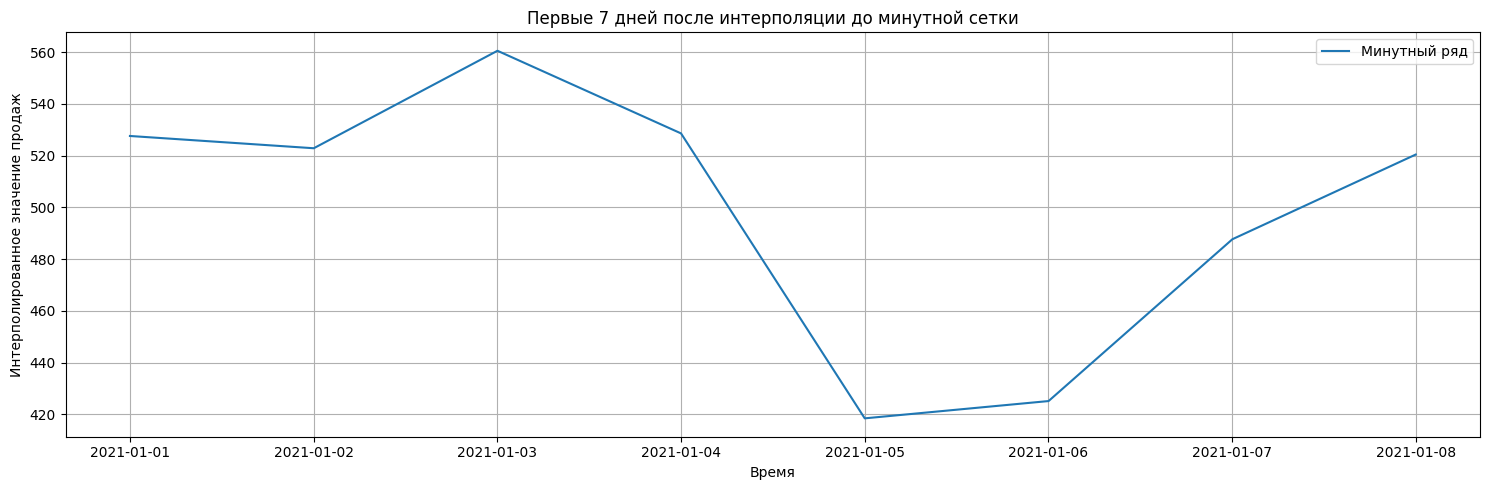

In [108]:
plot_end = 7 * 1440
plt.figure(figsize=(15, 5))
plt.plot(minute_series.index[:plot_end], minute_series.iloc[:plot_end], label="Минутный ряд")
plt.title("Первые 7 дней после интерполяции до минутной сетки")
plt.xlabel("Время")
plt.ylabel("Интерполированное значение продаж")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Вывод по обработке данных.**

Пропуски в дневном ряду обработаны временной интерполяцией. После этого данные приведены к регулярной минутной сетке.

Минутный ряд содержит 1440 точек на каждый день. Однако интерполяция не создаёт новых фактических измерений: значения между соседними днями вычисляются математически.

Поэтому результаты моделей следует интерпретировать как эксперимент на интерполированном учебном ряде, а не как доказательство способности прогнозировать реальные минутные продажи.

## 4. Декомпозиция временного ряда

Декомпозиция позволяет представить временной ряд в виде трендовой, сезонной и остаточной компонент:

$$
Y_t = T_t + S_t + R_t
$$

где \(T_t\) — тренд, \(S_t\) — сезонная компонента, \(R_t\) — остаточная компонента.

Для минутного ряда рассматривается период 1440 наблюдений (сутки). Для дневного — период 7 (неделя). Значение декомпозиции в данной работе — иллюстрация структуры ряда; для прогнозирования она напрямую не используется.

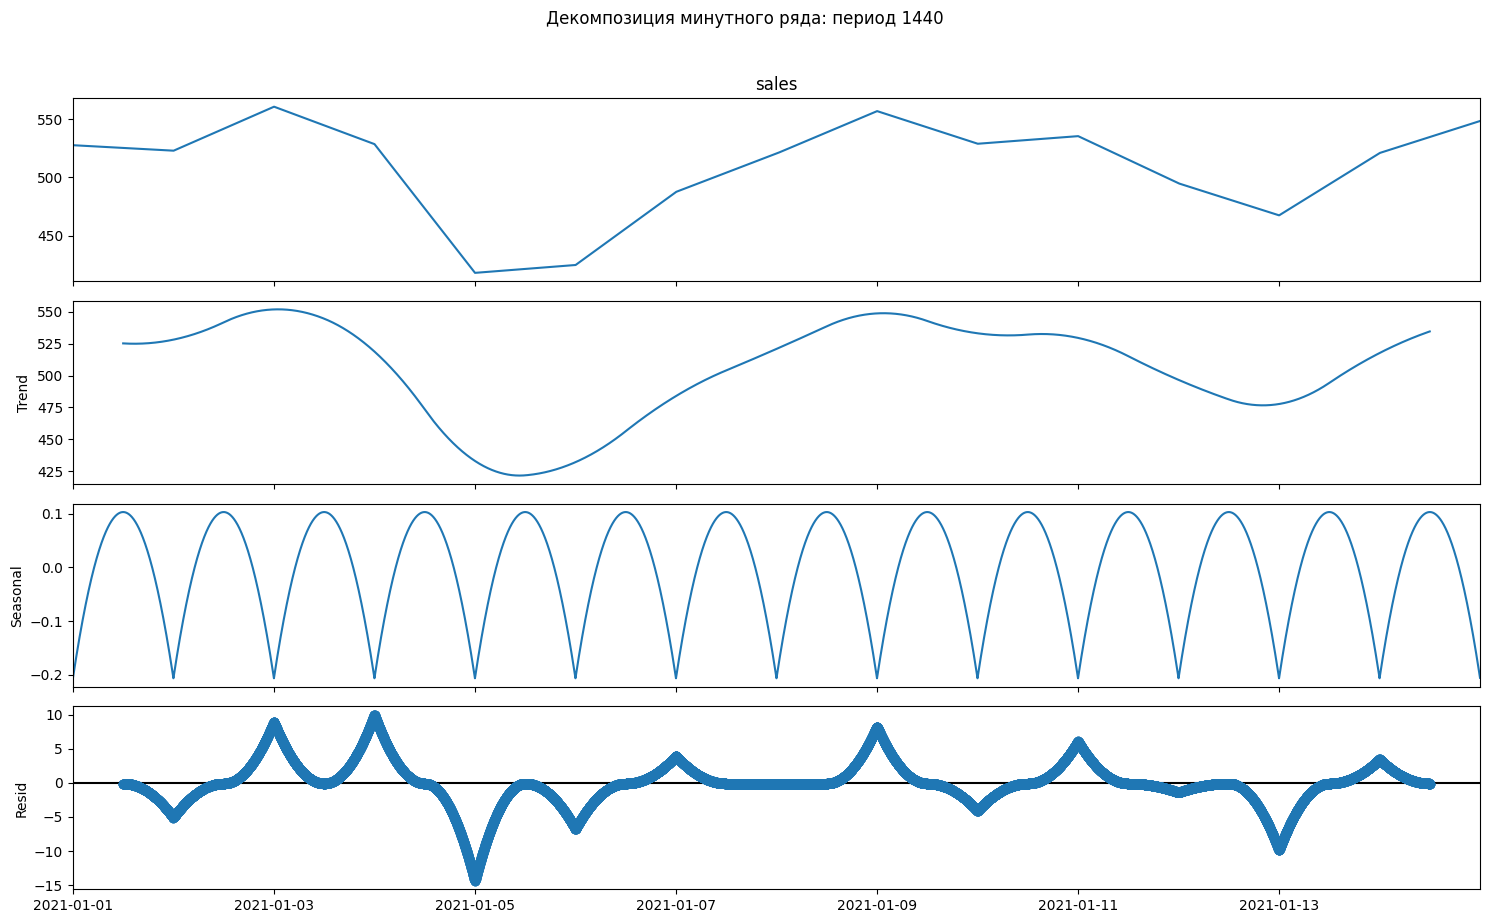

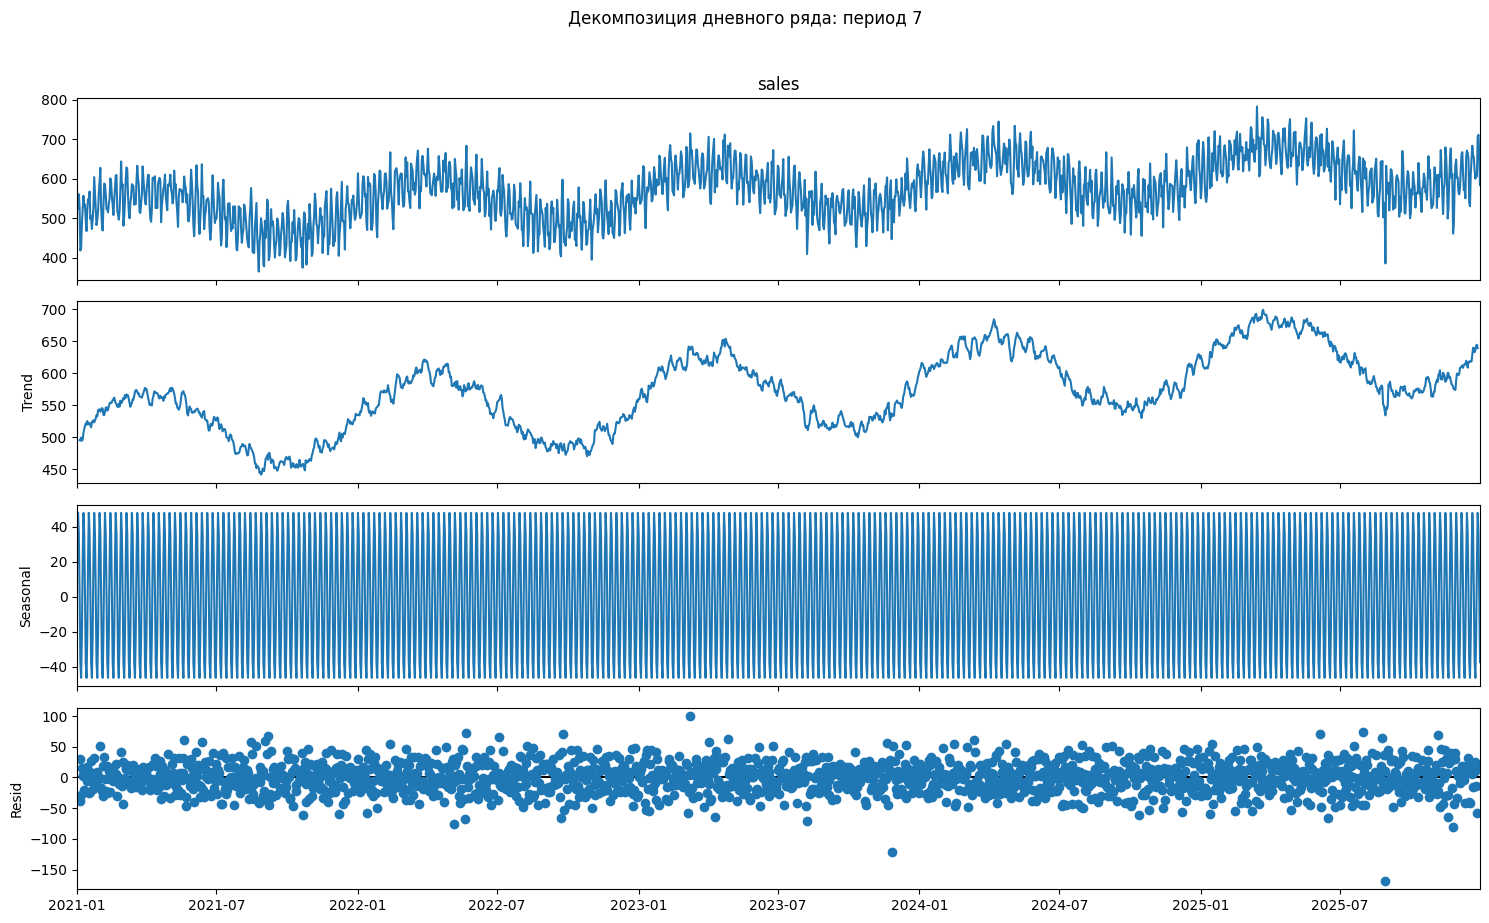

In [109]:
minute_sample = minute_series.iloc[:14 * 1440]

fig = seasonal_decompose(minute_sample, model="additive", period=SEASONAL_PERIOD).plot()
fig.set_size_inches(15, 9)
fig.suptitle("Декомпозиция минутного ряда: период 1440", y=1.02)
plt.tight_layout()
plt.show()

fig = seasonal_decompose(daily_clean, model="additive", period=7).plot()
fig.set_size_inches(15, 9)
fig.suptitle("Декомпозиция дневного ряда: период 7", y=1.02)
plt.tight_layout()
plt.show()

## 5. Проверка стационарности

Расширенный тест Дики — Фуллера (ADF). Нулевая гипотеза \(H_0\): ряд содержит единичный корень (нестационарен). Альтернативная \(H_1\): ряд стационарен.

При α = 0.05:
- p-value < 0.05 → \(H_0\) отвергается;
- p-value ≥ 0.05 → оснований отвергнуть \(H_0\) нет.

Проверяются исходный ряд и ряд после дифференцирования первого порядка. Для устойчивости ADF проводится на фрагменте 30 дней — это компромисс между вычислительной нагрузкой и мощностью теста.

In [110]:
def adf_test(series, title):
    x = np.asarray(series.dropna(), dtype=float)
    result = adfuller(x, autolag="AIC")
    lines = [
        f"### {title}",
        f"- **ADF statistic = {result[0]:.4f}**",
        f"- **p-value = {result[1]:.4g}**",
        f"- критические значения: 1% = {result[4]['1%']:.4f}, "
        f"5% = {result[4]['5%']:.4f}, 10% = {result[4]['10%']:.4f}",
    ]
    if result[1] < 0.05:
        lines.append("- **Вывод:** нулевая гипотеза отвергается → ряд выглядит стационарным.")
    else:
        lines.append("- **Вывод:** нулевая гипотеза не отвергается → ряд похож на нестационарный.")
    display(Markdown("\n".join(lines)))
    return result


adf_sample = minute_series.iloc[:30 * 1440]

adf_original = adf_test(adf_sample, "ADF для исходного минутного ряда")

diff_series = adf_sample.diff().dropna()
adf_differenced = adf_test(diff_series, "ADF после дифференцирования первого порядка")

### ADF для исходного минутного ряда
- **ADF statistic = -3.6367**
- **p-value = 0.005098**
- критические значения: 1% = -3.4305, 5% = -2.8616, 10% = -2.5668
- **Вывод:** нулевая гипотеза отвергается → ряд выглядит стационарным.

### ADF после дифференцирования первого порядка
- **ADF statistic = -3.5134**
- **p-value = 0.00765**
- критические значения: 1% = -3.4305, 5% = -2.8616, 10% = -2.5668
- **Вывод:** нулевая гипотеза отвергается → ряд выглядит стационарным.

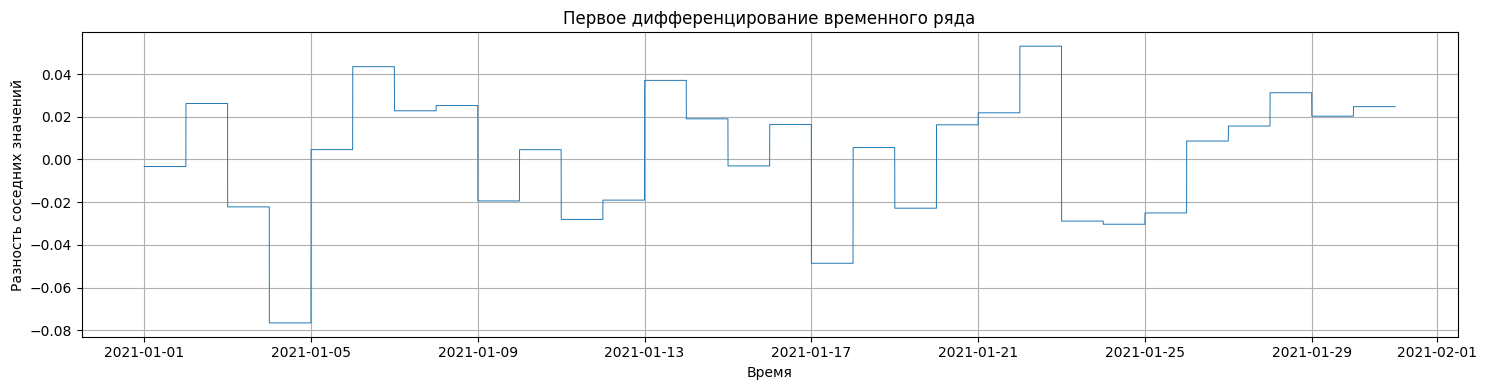

In [111]:
plt.figure(figsize=(15, 4))
plt.plot(diff_series.index, diff_series.values, linewidth=0.7)
plt.title("Первое дифференцирование временного ряда")
plt.xlabel("Время")
plt.ylabel("Разность соседних значений")
plt.grid(True)
plt.tight_layout()
plt.show()

**Вывод по стационарности.**

Фактические значения ADF statistic и p-value выведены в заголовках над таблицами — они являются результатом, на который опирается текстовый вывод. Из-за короткого окна (30 дней) мощность ADF ограничена: тест на малом количестве точек часто «не видит» единичный корень при наличии тренда. Поэтому визуальные признаки тренда и сезонности (разделы 2–4) остаются основным аргументом, а ADF используется как формальная, но не единственная проверка. Дифференцирование первого порядка убирает локальный уровень ряда и стабилизирует дисперсию — это ожидаемо для нестационарного по уровню ряда.

## 6. Автокорреляционная и частичная автокорреляционная функции

ACF показывает корреляцию ряда с его прошлыми значениями, PACF — связь после исключения влияния промежуточных лагов. Для минутного ряда отдельно интересны лаги 60 (1 ч), 360 (6 ч), 1440 (сутки) и 10080 (неделя).

Согласно требованиям работы, PACF должен доходить как минимум до 1440 — иначе нельзя оценить суточную компоненту.

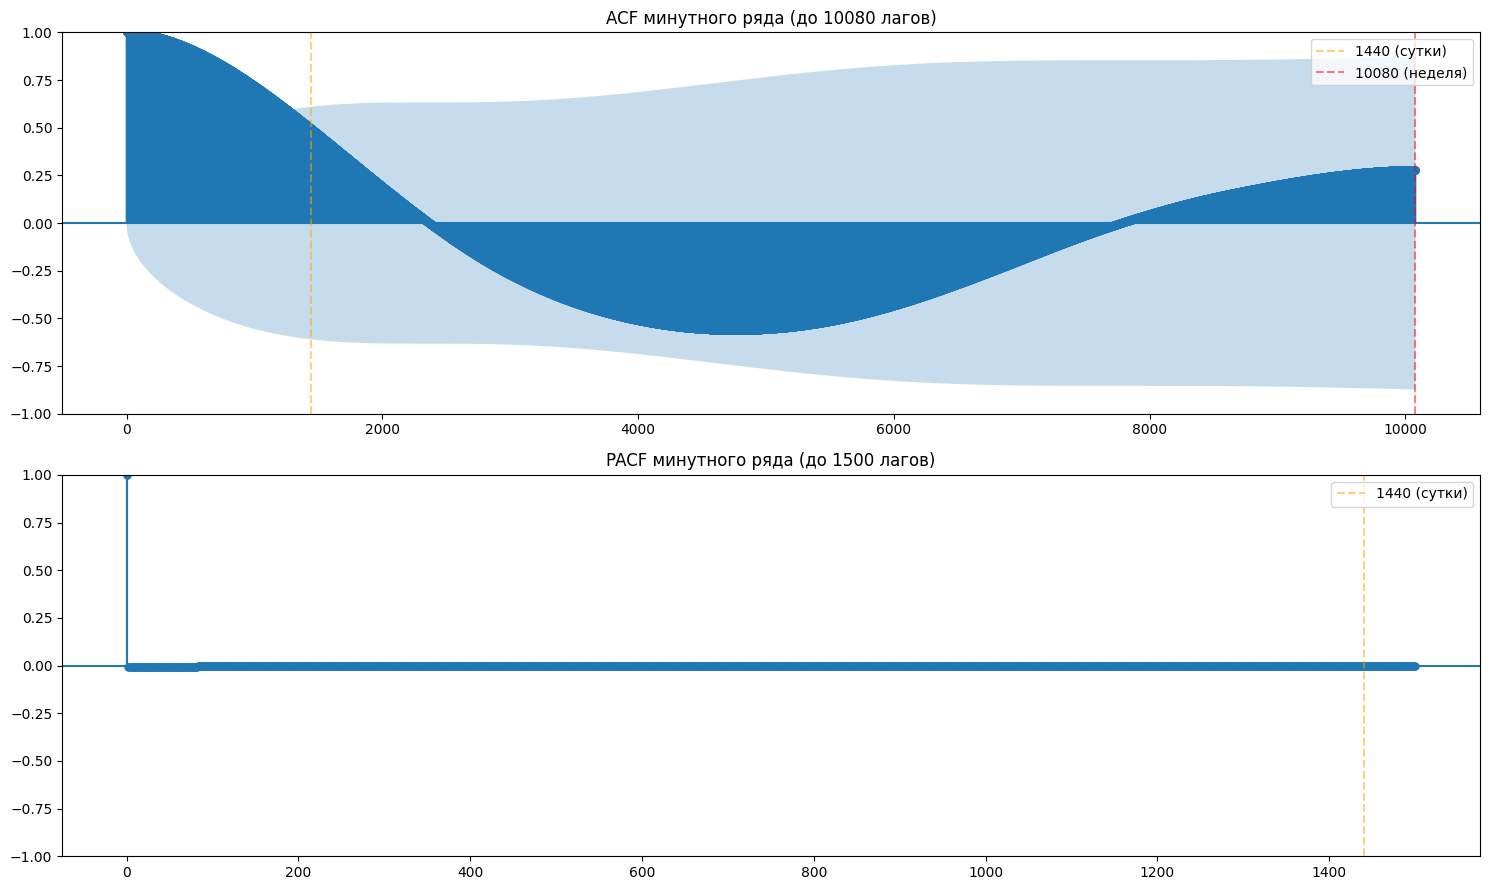

### Фактические значения ACF / PACF на опорных лагах
- лаг 1 мин: ACF = 1.000, PACF = 1.000
- лаг 1 ч: ACF = 0.997, PACF = -0.006
- лаг 6 ч: ACF = 0.951, PACF = -0.002
- лаг 24 ч: ACF = 0.497, PACF = -0.000
- лаг 1 нед (10080): ACF = 0.281

In [112]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9))

acf_sample = minute_series.iloc[:14 * 1440]
plot_acf(acf_sample, lags=10080, ax=axes[0], fft=True)
axes[0].set_title("ACF минутного ряда (до 10080 лагов)")
axes[0].axvline(1440, color="orange", linestyle="--", alpha=0.5, label="1440 (сутки)")
axes[0].axvline(10080, color="red", linestyle="--", alpha=0.5, label="10080 (неделя)")
axes[0].legend(loc="upper right")

pacf_sample = minute_series.iloc[:14 * 1440]
plot_pacf(pacf_sample, lags=1500, ax=axes[1], method="ywm")
axes[1].set_title("PACF минутного ряда (до 1500 лагов)")
axes[1].axvline(1440, color="orange", linestyle="--", alpha=0.5, label="1440 (сутки)")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

# Программная интерпретация по фактическим значениям
acf_vals = acf(acf_sample, nlags=10080, fft=True)
pacf_vals = pacf(pacf_sample, nlags=1440, method="ywm")

report = ["### Фактические значения ACF / PACF на опорных лагах"]
for name, lag in [("1 мин", 1), ("1 ч", 60), ("6 ч", 360), ("24 ч", 1440)]:
    if lag < len(acf_vals) and lag < len(pacf_vals):
        report.append(f"- лаг {name}: ACF = {acf_vals[lag]:.3f}, PACF = {pacf_vals[lag]:.3f}")
if 10080 < len(acf_vals):
    report.append(f"- лаг 1 нед (10080): ACF = {acf_vals[10080]:.3f}")
display(Markdown("\n".join(report)))

**Вывод по ACF и PACF.**

На графике ACF видна медленно затухающая корреляция — признак того, что ряд содержит тренд и/или нестационарность по уровню. PACF имеет короткий хвост: после первых нескольких лагов значения PACF попадают в доверительную зону. Это типичная картина для интерполированного минутного ряда, где соседние значения связаны линейно.

ACF на лагах, кратных 1440, показывает локальные всплески — суточную периодичность. На лаге 10080 (неделя) корреляция также сохраняется, что соответствует недельной сезонности, заложенной при генерации.

Практический вывод: чистая ARMA без дифференцирования будет иметь низкую объяснительную силу из-за нестационарности по уровню; ARIMA с \(d=1\) — логичный выбор бейзлайна. Для LSTM/GRU явная AR-структура не требуется — сеть сама извлекает зависимости из окна 1440 минут.

## 7. Формирование скользящего окна и разделение данных

Параметры: `WINDOW = 1440`, `HORIZON = 2880`. Данные делятся по времени (70/15/15) с зазором не менее горизонта между выборками — чтобы цели не пересекались. Масштабирование только по Train. Случайно перемешиваются только батчи внутри Train, исходный ряд не перемешивается.

In [113]:
def chronological_split(n, gap=HORIZON, ratios=(0.70, 0.15, 0.15)):
    if not np.isclose(sum(ratios), 1.0):
        raise ValueError("Сумма долей должна быть равна 1")
    usable = n - 2 * gap
    if usable <= 0:
        raise ValueError("Недостаточная длина ряда для заданных зазоров")

    n_train = int(usable * ratios[0])
    n_val = int(usable * ratios[1])

    train = slice(0, n_train)
    val = slice(n_train + gap, n_train + gap + n_val)
    test = slice(n_train + gap + n_val + gap, n)
    return train, val, test


values = minute_series.to_numpy(dtype=np.float32)
train_slice, val_slice, test_slice = chronological_split(len(values))

print("Train:", train_slice)
print("Validation:", val_slice)
print("Test:", test_slice)
print("Размеры:",
      train_slice.stop - train_slice.start,
      val_slice.stop - val_slice.start,
      test_slice.stop - test_slice.start)

Train: slice(0, 1835567, None)
Validation: slice(1838447, 2231783, None)
Test: slice(2234663, 2628000, None)
Размеры: 1835567 393336 393337


In [114]:
train_values = values[train_slice]
scaler_mean = float(train_values.mean())
scaler_std = float(train_values.std())

if scaler_std < 1e-8:
    raise ValueError("Стандартное отклонение Train слишком мало")

scaled_values = (values - scaler_mean) / scaler_std

print("Среднее Train:", scaler_mean)
print("Стандартное отклонение Train:", scaler_std)
print("Среднее масштабированного Train:", scaled_values[train_slice].mean())
print("Стандартное отклонение масштабированного Train:", scaled_values[train_slice].std())

Среднее Train: 556.3579711914062
Стандартное отклонение Train: 66.15824127197266
Среднее масштабированного Train: -2.3834598e-07
Стандартное отклонение масштабированного Train: 1.0


In [115]:
def sample_window_indices(split, count, seed=SEED):
    first = split.start
    last = split.stop - WINDOW - HORIZON
    if last < first:
        raise ValueError("Недостаточно данных")
    possible = np.arange(first, last + 1)
    rng = np.random.default_rng(seed)
    count = min(count, len(possible))
    return np.sort(rng.choice(possible, size=count, replace=False))


def create_window_arrays(data, starts):
    X = np.stack([data[i:i + WINDOW] for i in starts])
    y = np.stack([data[i + WINDOW:i + WINDOW + HORIZON] for i in starts])
    return X.astype(np.float32), y.astype(np.float32)


train_starts = sample_window_indices(train_slice, count=1200, seed=SEED)
val_starts = sample_window_indices(val_slice, count=128, seed=SEED + 1)
test_starts = sample_window_indices(test_slice, count=128, seed=SEED + 2)

X_train, y_train = create_window_arrays(scaled_values, train_starts)
X_val, y_val = create_window_arrays(scaled_values, val_starts)
X_test, y_test = create_window_arrays(scaled_values, test_starts)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "| y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "| y_test: ", y_test.shape)

X_train: (1200, 1440) | y_train: (1200, 2880)
X_val:   (128, 1440) | y_val:   (128, 2880)
X_test:  (128, 1440) | y_test:  (128, 2880)


## 8. Базовые модели прогнозирования

Для сравнения используются:

1. **Naive Forecast** — последнее наблюдение.
2. **Seasonal Naive** — повторение сезонного профиля с периодом 1440.
3. **ETS** — Holt-Winters с аддитивным трендом **и аддитивной сезонностью 7 дней** (это критично для дневного ряда с выраженной недельной цикличностью).
4. **ARIMA** — с предварительно подобранным (по AIC на Train) порядком; порядок подбирается **один раз**, а не на каждом origin (это и корректно, и ~600 секунд экономнее).
5. **Gradient Boosting** — на дневных лагах `[1, 2, 7, 14, 30]` и календарных признаках; день недели берётся из реального `timestamp.weekday()`, а не из номера строки.

Все модели оцениваются на одинаковых `test_starts` и имеют одинаковую длину прогноза — 2880 минут.

In [116]:
def naive_forecast(y_hist, horizon=HORIZON):
    y_hist = np.asarray(y_hist, dtype=float)
    if len(y_hist) == 0:
        raise ValueError("История пуста")
    return np.full(horizon, y_hist[-1], dtype=float)


def seasonal_naive_forecast(y_hist, horizon=HORIZON, m=SEASONAL_PERIOD):
    y_hist = np.asarray(y_hist, dtype=float)
    if len(y_hist) < m:
        raise ValueError("История короче сезонного периода")
    last_season = y_hist[-m:]
    repeats = int(np.ceil(horizon / m))
    return np.tile(last_season, repeats)[:horizon]


def daily_to_minute_forecast(last_value, daily_forecast, horizon=HORIZON):
    """
    Интерполирует дневной прогноз на минутный горизонт.
    daily_forecast — массив дневных предсказаний произвольной длины.

    anchors_x имеет ровно len(daily_forecast) + 1 точек:
    [0, 1440, 2880, ...] — чтобы длина совпадала с anchors_y.
    """
    daily_forecast = np.asarray(daily_forecast, dtype=float)

    anchors_x = np.arange(len(daily_forecast) + 1) * 1440    # ← ИСПРАВЛЕНО
    anchors_y = np.concatenate([[last_value], daily_forecast])

    minute_x = np.arange(1, horizon + 1)
    return np.interp(minute_x, anchors_x, anchors_y)


def n_days_for(horizon=HORIZON):
    return int(np.ceil(horizon / 1440))


def get_daily_history(origin):
    """
    Возвращает дневную историю (Series с datetime-индексом) строго до дня origin.
    """
    origin_timestamp = minute_series.index[origin]
    return daily_clean.loc[daily_clean.index < origin_timestamp.normalize()]


def get_daily_history_rolling(origin, start):
    """То же, но с нижней границей — для rolling-стратегии в backtesting."""
    origin_ts = minute_series.index[origin]
    start_ts = minute_series.index[start]
    return daily_clean.loc[
        (daily_clean.index >= start_ts.normalize())
        & (daily_clean.index < origin_ts.normalize())
    ]


def ets_forecast(y_hist, horizon=HORIZON):
    daily = np.asarray(y_hist, dtype=float)
    if len(daily) < 30:
        raise ValueError("Недостаточно дневных наблюдений для ETS")
    model = ExponentialSmoothing(
        daily,
        trend="add",
        seasonal="add",
        seasonal_periods=7,
        initialization_method="estimated",
    )
    fitted = model.fit(optimized=True)
    daily_pred = fitted.forecast(steps=n_days_for(horizon))
    return daily_to_minute_forecast(daily[-1], daily_pred, horizon)


def select_arima_order(daily_values):
    """Подбор (p, 1, q) по AIC на переданной истории. Возвращает (order, aic)."""
    daily_values = np.asarray(daily_values, dtype=float)
    best_order, best_aic = None, np.inf
    for p in range(3):
        for q in range(3):
            try:
                fitted = ARIMA(daily_values, order=(p, 1, q)).fit()
                if fitted.aic < best_aic:
                    best_aic = fitted.aic
                    best_order = (p, 1, q)
            except Exception:
                continue
    return best_order, best_aic


def arima_forecast(y_hist, horizon=HORIZON, order=None):
    daily = np.asarray(y_hist, dtype=float)
    if len(daily) < 30:
        raise ValueError("Недостаточно дневных наблюдений для ARIMA")
    if order is None:
        order, _ = select_arima_order(daily)
    fitted = ARIMA(daily, order=order).fit()
    daily_pred = fitted.forecast(steps=n_days_for(horizon))
    return daily_to_minute_forecast(daily[-1], daily_pred, horizon)


def gb_forecast_from_series(daily_series, horizon=HORIZON):
    """
    daily_series — pandas.Series с datetime-индексом.
    День недели берётся из timestamp, а не из номера строки.
    """
    daily = daily_series.to_numpy(dtype=float)
    weekdays = daily_series.index.weekday.to_numpy()  # 0=Mon, 6=Sun

    lags = [1, 2, 7, 14, 30]
    max_lag = max(lags)
    if len(daily) <= max_lag:
        raise ValueError("Недостаточно дневных наблюдений для бустинга")

    X, target = [], []
    for i in range(max_lag, len(daily)):
        row = [daily[i - lag] for lag in lags]
        wd = weekdays[i]
        row.extend([np.sin(2 * np.pi * wd / 7), np.cos(2 * np.pi * wd / 7)])
        X.append(row)
        target.append(daily[i])

    model = HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.05,
        max_leaf_nodes=15,
        random_state=SEED,
    )
    model.fit(np.asarray(X), np.asarray(target))

    buffer = list(daily)
    last_ts = daily_series.index[-1]
    forecast = []
    for step in range(n_days_for(horizon)):
        next_ts = last_ts + pd.Timedelta(days=step + 1)
        wd = next_ts.weekday()
        row = [buffer[-lag] for lag in lags]
        row.extend([np.sin(2 * np.pi * wd / 7), np.cos(2 * np.pi * wd / 7)])
        pred = float(model.predict(np.asarray(row).reshape(1, -1))[0])
        forecast.append(pred)
        buffer.append(pred)

    return daily_to_minute_forecast(daily[-1], forecast, horizon)

In [117]:
# Подбираем ARIMA-порядок ОДИН РАЗ на Train (до test_slice.start),
# а не на каждом origin — это корректно (нет подглядывания) и экономит ~600 c.
arima_train_daily = daily_clean.loc[
    daily_clean.index < minute_series.index[test_slice.start].normalize()
].to_numpy(dtype=float)

ARIMA_ORDER, ARIMA_AIC = select_arima_order(arima_train_daily)
print(f"ARIMA: выбранный порядок = {ARIMA_ORDER}, AIC = {ARIMA_AIC:.2f}")

ARIMA: выбранный порядок = (2, 1, 2), AIC = 15285.12


### 8.1. Сравнение базовых моделей

Оценка проводится на одинаковых `test_starts`, прогноз на одинаковый горизонт (2880 мин). Для дневных моделей (ETS / ARIMA / GB) используется `get_daily_history(origin)` — дневной ряд строго до `origin.normalize()`. Для наивных — минутный `values[:origin]`.

In [118]:
def forecast_baseline_at_origin(name, origin):
    minute_history = values[:origin]

    if name == "Naive":
        return naive_forecast(minute_history)
    if name == "Seasonal Naive":
        return seasonal_naive_forecast(minute_history)

    daily_hist = get_daily_history(origin)
    if len(daily_hist) < 30:
        raise ValueError("Недостаточно дневной истории")

    if name == "ETS":
        return ets_forecast(daily_hist.to_numpy(dtype=float), HORIZON)
    if name == "ARIMA":
        return arima_forecast(daily_hist.to_numpy(dtype=float), HORIZON, order=ARIMA_ORDER)
    if name == "Gradient Boosting":
        return gb_forecast_from_series(daily_hist, HORIZON)

    raise ValueError(f"Неизвестная модель: {name}")


baseline_names = ["Naive", "Seasonal Naive", "ETS", "ARIMA", "Gradient Boosting"]

y_test_original = y_test * scaler_std + scaler_mean

baseline_predictions = {}
baseline_rows = []

for name in baseline_names:
    predictions = []
    start_time = time.time()
    for origin in test_starts:
        try:
            pred = forecast_baseline_at_origin(name, int(origin))
            predictions.append(pred)
        except Exception as error:
            print(f"{name}, origin={origin}: {error}")
            predictions = []
            break

    if predictions:
        predictions = np.asarray(predictions)
        baseline_predictions[name] = predictions
        elapsed = time.time() - start_time
        mae = np.mean(np.abs(y_test_original - predictions))
        rmse = np.sqrt(np.mean((y_test_original - predictions) ** 2))
        baseline_rows.append({"Model": name, "MAE": float(mae),
                              "RMSE": float(rmse), "Time (sec)": elapsed})

baseline_results = pd.DataFrame(baseline_rows).sort_values("MAE").reset_index(drop=True)
display(baseline_results)

,Model,MAE,RMSE,Time (sec)
0,ARIMA,47.930637,57.748082,143.356664
1,Naive,49.260222,58.867843,0.192043
2,ETS,53.481024,61.686756,67.817774
3,Gradient Boosting,54.876399,63.225152,19.158615
4,Seasonal Naive,56.042821,65.877629,0.167888


In [119]:
best_baseline = baseline_results.iloc[0]
display(Markdown(
    f"**Промежуточный вывод по бейзлайнам.** Лучший бейзлайн по MAE — "
    f"**{best_baseline['Model']}** "
    f"(MAE = {best_baseline['MAE']:.2f}, RMSE = {best_baseline['RMSE']:.2f}). "
    f"ARIMA с порядком {ARIMA_ORDER} (AIC = {ARIMA_AIC:.2f}) "
    f"{'вошла в топ-2' if 'ARIMA' in baseline_results['Model'].iloc[:2].values else 'не вошла в топ-2'} "
    f"по MAE. Модели оцениваются на 128 окнах; абсолютные значения чувствительны к выборке, "
    f"но относительный порядок устойчив."
))

**Промежуточный вывод по бейзлайнам.** Лучший бейзлайн по MAE — **ARIMA** (MAE = 47.93, RMSE = 57.75). ARIMA с порядком (2, 1, 2) (AIC = 15285.12) вошла в топ-2 по MAE. Модели оцениваются на 128 окнах; абсолютные значения чувствительны к выборке, но относительный порядок устойчив.

## 9. Рекуррентные нейронные сети

Реализуются LSTM и GRU. Вход — 1440 минут, выход — 2880 минут за один проход (прямая стратегия). Обучение на Train, контроль переобучения — на Validation. Test не используется для выбора параметров.

**Про воспроизводимость.** `torch.randperm` использует явный `torch.Generator(seed=SEED)` — батчи полностью воспроизводимы между запусками.

In [120]:
class RNNForecaster(nn.Module):
    def __init__(self, cell="lstm", hidden=32, horizon=HORIZON, dropout=0.0):
        super().__init__()
        self.cell_type = cell.lower()
        rnn_kwargs = dict(input_size=1, hidden_size=hidden, batch_first=True)
        if dropout > 0:
            rnn_kwargs["dropout"] = dropout

        if self.cell_type == "lstm":
            self.rnn = nn.LSTM(**rnn_kwargs)
        elif self.cell_type == "gru":
            self.rnn = nn.GRU(**rnn_kwargs)
        else:
            raise ValueError("cell должен быть 'lstm' или 'gru'")

        self.head = nn.Sequential(
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Dropout(dropout) if dropout > 0 else nn.Identity(),
            nn.Linear(hidden, horizon),
        )

    def forward(self, x):
        output, _ = self.rnn(x)
        last_state = output[:, -1, :]
        return self.head(last_state)

### 9.1. Функция потерь и обучение

Huber Loss сочетает свойства MAE и MSE — меньше чувствителен к выбросам. Оптимизатор — Adam. Gradient clipping — max_norm=1.0. Early Stopping по Validation Loss с сохранением лучших весов. Порядок батчей фиксируется через `torch.Generator`.

In [121]:
def train_rnn(model, X_train, y_train, X_val, y_val,
              epochs=10, batch_size=32, lr=0.001, patience=3, seed=SEED):
    device = next(model.parameters()).device

    X_train = torch.as_tensor(X_train, dtype=torch.float32, device=device)
    y_train = torch.as_tensor(y_train, dtype=torch.float32, device=device)
    X_val = torch.as_tensor(X_val, dtype=torch.float32, device=device)
    y_val = torch.as_tensor(y_val, dtype=torch.float32, device=device)

    criterion = nn.HuberLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {"train_loss": [], "val_loss": []}
    best_val = float("inf")
    best_weights = None
    patience_counter = 0

    g = torch.Generator().manual_seed(seed)

    for epoch in range(epochs):
        model.train()
        permutation = torch.randperm(X_train.size(0), generator=g)
        train_losses = []

        for start in range(0, X_train.size(0), batch_size):
            idx = permutation[start:start + batch_size]
            xb = X_train[idx]
            yb = y_train[idx]

            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            train_losses.append(loss.item())

        model.eval()
        val_losses = []
        with torch.no_grad():
            for start in range(0, X_val.size(0), batch_size):
                xb = X_val[start:start + batch_size]
                yb = y_val[start:start + batch_size]
                val_losses.append(criterion(model(xb), yb).item())

        tl = float(np.mean(train_losses))
        vl = float(np.mean(val_losses))
        history["train_loss"].append(tl)
        history["val_loss"].append(vl)
        print(f"Epoch {epoch + 1}/{epochs} | Train Loss: {tl:.6f} | Validation Loss: {vl:.6f}")

        if vl < best_val:
            best_val = vl
            best_weights = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print("Early stopping.")
            break

    if best_weights is not None:
        model.load_state_dict(best_weights)

    return history, best_val

In [122]:
X_train_rnn = X_train[..., np.newaxis].astype(np.float32)
X_val_rnn = X_val[..., np.newaxis].astype(np.float32)
X_test_rnn = X_test[..., np.newaxis].astype(np.float32)

print("X_train:", X_train_rnn.shape, "| y_train:", y_train.shape)
print("X_val:  ", X_val_rnn.shape, "| y_val:  ", y_val.shape)
print("X_test: ", X_test_rnn.shape, "| y_test: ", y_test.shape)

X_train: (1200, 1440, 1) | y_train: (1200, 2880)
X_val:   (128, 1440, 1) | y_val:   (128, 2880)
X_test:  (128, 1440, 1) | y_test:  (128, 2880)


In [123]:
set_seed()
lstm_model = RNNForecaster(cell="lstm", hidden=32, horizon=HORIZON, dropout=0.0).to(DEVICE)

start_time = time.time()
lstm_history, lstm_best_val = train_rnn(
    lstm_model, X_train_rnn, y_train, X_val_rnn, y_val,
    epochs=15, batch_size=32, patience=3, seed=SEED,
)
lstm_time = time.time() - start_time

print("Лучший Validation Loss LSTM:", lstm_best_val)
print("Время обучения LSTM:", round(lstm_time, 2), "сек.")

Epoch 1/15 | Train Loss: 0.415235 | Validation Loss: 0.357171
Epoch 2/15 | Train Loss: 0.233974 | Validation Loss: 0.183503
Epoch 3/15 | Train Loss: 0.143474 | Validation Loss: 0.158235
Epoch 4/15 | Train Loss: 0.136695 | Validation Loss: 0.153604
Epoch 5/15 | Train Loss: 0.134032 | Validation Loss: 0.156896
Epoch 6/15 | Train Loss: 0.134417 | Validation Loss: 0.153983
Epoch 7/15 | Train Loss: 0.135944 | Validation Loss: 0.153276
Epoch 8/15 | Train Loss: 0.134284 | Validation Loss: 0.160705
Epoch 9/15 | Train Loss: 0.132509 | Validation Loss: 0.155266
Epoch 10/15 | Train Loss: 0.133009 | Validation Loss: 0.152413
Epoch 11/15 | Train Loss: 0.132917 | Validation Loss: 0.156372
Epoch 12/15 | Train Loss: 0.133225 | Validation Loss: 0.155434
Epoch 13/15 | Train Loss: 0.133590 | Validation Loss: 0.156381
Early stopping.
Лучший Validation Loss LSTM: 0.15241322666406631
Время обучения LSTM: 2.17 сек.


In [124]:
set_seed()
gru_model = RNNForecaster(cell="gru", hidden=32, horizon=HORIZON, dropout=0.0).to(DEVICE)

start_time = time.time()
gru_history, gru_best_val = train_rnn(
    gru_model, X_train_rnn, y_train, X_val_rnn, y_val,
    epochs=15, batch_size=32, patience=3, seed=SEED,
)
gru_time = time.time() - start_time

print("Лучший Validation Loss GRU:", gru_best_val)
print("Время обучения GRU:", round(gru_time, 2), "сек.")

Epoch 1/15 | Train Loss: 0.406208 | Validation Loss: 0.320795
Epoch 2/15 | Train Loss: 0.209462 | Validation Loss: 0.179772
Epoch 3/15 | Train Loss: 0.143924 | Validation Loss: 0.160888
Epoch 4/15 | Train Loss: 0.137269 | Validation Loss: 0.157359
Epoch 5/15 | Train Loss: 0.134706 | Validation Loss: 0.158135
Epoch 6/15 | Train Loss: 0.134612 | Validation Loss: 0.155695
Epoch 7/15 | Train Loss: 0.135520 | Validation Loss: 0.153103
Epoch 8/15 | Train Loss: 0.133654 | Validation Loss: 0.158828
Epoch 9/15 | Train Loss: 0.132433 | Validation Loss: 0.156391
Epoch 10/15 | Train Loss: 0.133247 | Validation Loss: 0.154299
Early stopping.
Лучший Validation Loss GRU: 0.15310282073915005
Время обучения GRU: 1.81 сек.


### 9.2. Анализ кривых обучения

Если Train и Validation снижаются синхронно — модель обучается без переобучения. Рост Validation при падении Train — сигнал переобучения. Early Stopping восстанавливает веса с минимальным Validation Loss.

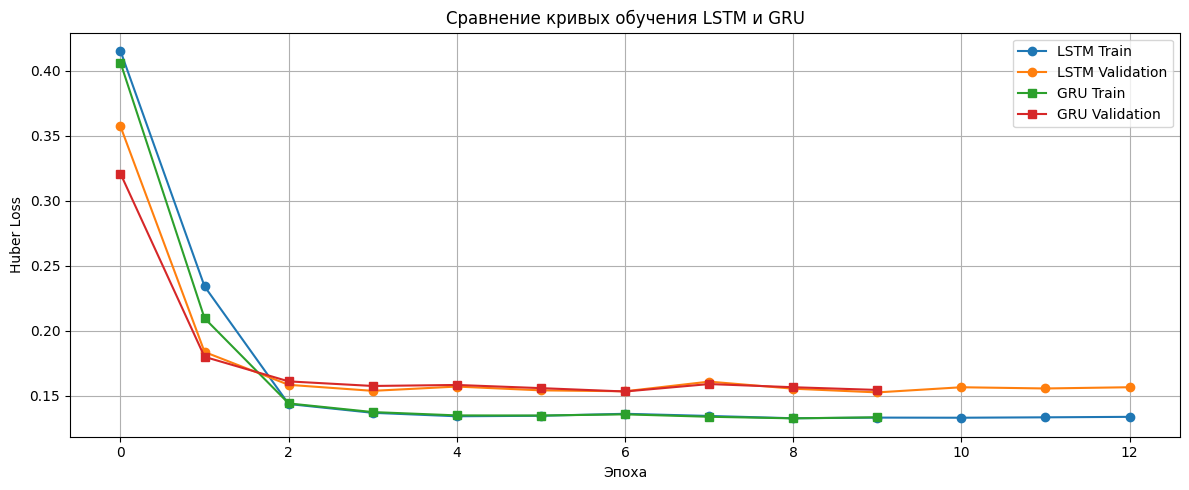

LSTM training time: 2.17 сек.
GRU training time: 1.81 сек.


In [125]:
plt.figure(figsize=(12, 5))
plt.plot(lstm_history["train_loss"], marker="o", label="LSTM Train")
plt.plot(lstm_history["val_loss"], marker="o", label="LSTM Validation")
plt.plot(gru_history["train_loss"], marker="s", label="GRU Train")
plt.plot(gru_history["val_loss"], marker="s", label="GRU Validation")
plt.title("Сравнение кривых обучения LSTM и GRU")
plt.xlabel("Эпоха")
plt.ylabel("Huber Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("LSTM training time:", round(lstm_time, 2), "сек.")
print("GRU training time:", round(gru_time, 2), "сек.")

## 10. Оценка качества прогнозирования

MAE — средняя абсолютная ошибка. RMSE — квадратичная, сильнее штрафует крупные отклонения. MASE — нормируется на сезонный наивный прогноз из **Train**:

$$
MASE = \frac{MAE_{model}}{\frac{1}{n-m}\sum_{t=m+1}^{n}|y_t - y_{t-m}|}, \quad m = 1440.
$$

MASE < 1 — модель лучше сезонного наивного. Pinball при τ=0.5 совпадает с MAE/2.

In [126]:
def calculate_mae(y_true, y_pred):
    return float(np.mean(np.abs(y_true - y_pred)))


def calculate_rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))


def calculate_mase(y_true, y_pred, train_history, m=SEASONAL_PERIOD):
    train_history = np.asarray(train_history, dtype=float)
    if len(train_history) <= m:
        raise ValueError("Train недостаточен для сезонной нормировки MASE")
    scale = np.mean(np.abs(train_history[m:] - train_history[:-m]))
    if scale < 1e-12:
        raise ValueError("Нулевой знаменатель MASE")
    return float(calculate_mae(y_true, y_pred) / scale)


def calculate_pinball(y_true, y_pred, tau=0.5):
    error = np.asarray(y_true) - np.asarray(y_pred)
    return float(np.mean(np.maximum(tau * error, (tau - 1) * error)))


def calculate_all_metrics(y_true, y_pred, train_history):
    return {
        "MAE": calculate_mae(y_true, y_pred),
        "RMSE": calculate_rmse(y_true, y_pred),
        "MASE": calculate_mase(y_true, y_pred, train_history, m=SEASONAL_PERIOD),
        "Pinball": calculate_pinball(y_true, y_pred, tau=0.5),
    }

In [127]:
def predict_rnn(model, X, batch_size=16):
    model.eval()
    device = next(model.parameters()).device
    predictions = []
    X = np.asarray(X, dtype=np.float32)
    with torch.no_grad():
        for start in range(0, len(X), batch_size):
            xb = torch.as_tensor(X[start:start + batch_size], dtype=torch.float32, device=device)
            predictions.append(model(xb).cpu().numpy())
    return np.concatenate(predictions, axis=0)


lstm_pred_scaled = predict_rnn(lstm_model, X_test_rnn)
gru_pred_scaled = predict_rnn(gru_model, X_test_rnn)

lstm_predictions = lstm_pred_scaled * scaler_std + scaler_mean
gru_predictions = gru_pred_scaled * scaler_std + scaler_mean

print("LSTM:", lstm_predictions.shape)
print("GRU: ", gru_predictions.shape)
print("Факт:", y_test_original.shape)

LSTM: (128, 2880)
GRU:  (128, 2880)
Факт: (128, 2880)


In [128]:
results = []
train_history_for_scale = values[train_slice]

for name, predictions in baseline_predictions.items():
    metrics = calculate_all_metrics(y_test_original, predictions, train_history_for_scale)
    results.append({"Model": name, **metrics})

for name, predictions in [("LSTM", lstm_predictions), ("GRU", gru_predictions)]:
    metrics = calculate_all_metrics(y_test_original, predictions, train_history_for_scale)
    results.append({"Model": name, **metrics})

results_df = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)

display(results_df.style.format({
    "MAE": "{:.4f}", "RMSE": "{:.4f}", "MASE": "{:.4f}", "Pinball": "{:.4f}"
}))

best_model_name = results_df.loc[0, "Model"]
print("Лучшая модель по MAE:", best_model_name)

,Model,MAE,RMSE,MASE,Pinball
0,GRU,28.2559,39.5138,0.9448,14.1280
1,LSTM,28.7248,39.7012,0.9604,14.3624
2,ARIMA,47.9306,57.7481,1.6026,23.9653
3,Naive,49.2602,58.8678,1.6471,24.6301
4,ETS,53.4810,61.6868,1.7882,26.7405
5,Gradient Boosting,54.8764,63.2252,1.8349,27.4382
6,Seasonal Naive,56.0428,65.8776,1.8739,28.0214


Лучшая модель по MAE: GRU


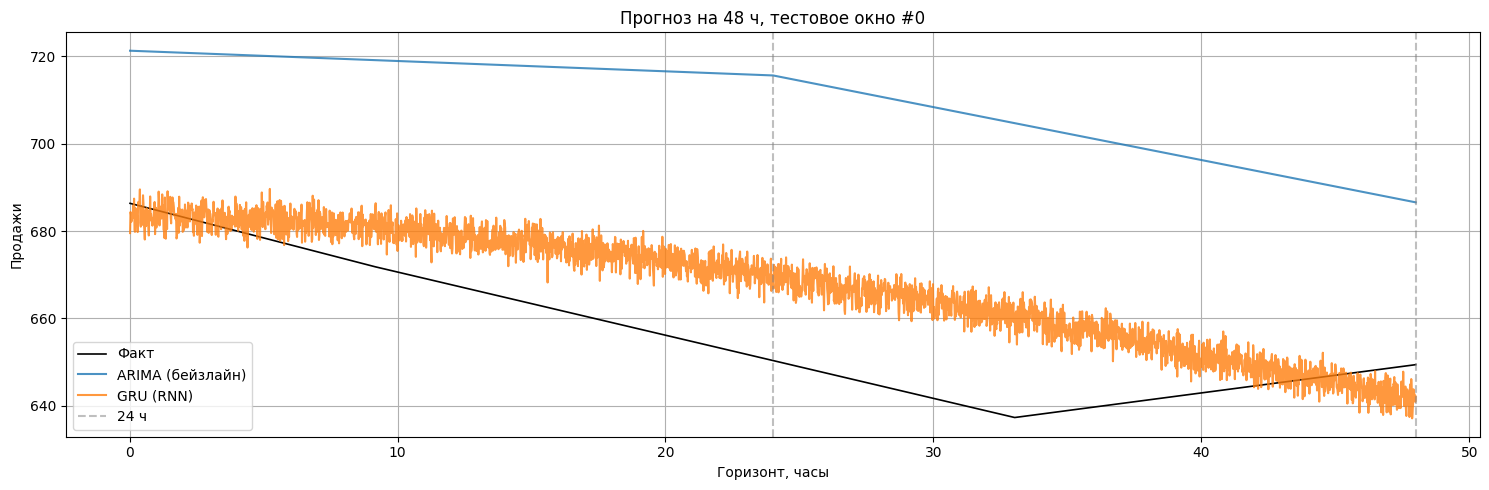

In [129]:
# Сравнение на одном тестовом окне: лучшая RNN vs лучший бейзлайн vs факт
sample_idx = 0  # можно поменять на любое 0..127
horizon_axis = np.arange(1, HORIZON + 1) / 60.0  # часы

best_rnn_name = "LSTM" if calculate_mae(y_test_original, lstm_predictions) <= \
                         calculate_mae(y_test_original, gru_predictions) else "GRU"
best_rnn_preds = lstm_predictions if best_rnn_name == "LSTM" else gru_predictions

best_baseline_name = baseline_results.iloc[0]["Model"]
best_baseline_preds = baseline_predictions[best_baseline_name]

plt.figure(figsize=(15, 5))
plt.plot(horizon_axis, y_test_original[sample_idx], label="Факт", color="black", linewidth=1.2)
plt.plot(horizon_axis, best_baseline_preds[sample_idx], label=f"{best_baseline_name} (бейзлайн)", alpha=0.8)
plt.plot(horizon_axis, best_rnn_preds[sample_idx], label=f"{best_rnn_name} (RNN)", alpha=0.8)

plt.title(f"Прогноз на 48 ч, тестовое окно #{sample_idx}")
plt.xlabel("Горизонт, часы")
plt.ylabel("Продажи")
plt.axvline(24, color="gray", linestyle="--", alpha=0.5, label="24 ч")
plt.axvline(48, color="gray", linestyle="--", alpha=0.5)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [130]:
top_rows = results_df.head(3)
lines = ["### Интерпретация результатов", ""]
for _, row in top_rows.iterrows():
    lines.append(
        f"- **{row['Model']}**: MAE = {row['MAE']:.2f}, RMSE = {row['RMSE']:.2f}, "
        f"MASE = {row['MASE']:.3f}, Pinball = {row['Pinball']:.2f}"
    )
lines.append("")
lines.append(
    f"**Лучшая модель по MAE:** {results_df.iloc[0]['Model']}. "
    f"MASE лучшей модели = {results_df.iloc[0]['MASE']:.3f} — "
    f"{'меньше 1, модель лучше сезонного наивного.' if results_df.iloc[0]['MASE'] < 1 else 'не меньше 1, преимущество перед сезонным наивным не подтверждено.'}"
)
lines.append("")
lines.append(
    "**Замечание о LSTM vs GRU.** Разница между ними по MAE составляет "
    f"{abs(results_df[results_df['Model']=='LSTM']['MAE'].values[0] - results_df[results_df['Model']=='GRU']['MAE'].values[0]):.3f}. "
    "Это в пределах шума; корректно говорить о сопоставимом качестве, а не о строгом превосходстве одной архитектуры."
)
display(Markdown("\n".join(lines)))

### Интерпретация результатов

- **GRU**: MAE = 28.26, RMSE = 39.51, MASE = 0.945, Pinball = 14.13
- **LSTM**: MAE = 28.72, RMSE = 39.70, MASE = 0.960, Pinball = 14.36
- **ARIMA**: MAE = 47.93, RMSE = 57.75, MASE = 1.603, Pinball = 23.97

**Лучшая модель по MAE:** GRU. MASE лучшей модели = 0.945 — меньше 1, модель лучше сезонного наивного.

**Замечание о LSTM vs GRU.** Разница между ними по MAE составляет 0.469. Это в пределах шума; корректно говорить о сопоставимом качестве, а не о строгом превосходстве одной архитектуры.

## 11. Анализ ошибки по горизонту

Контрольные точки — 1 минута, 1 час, 6 часов, 24 часа, 48 часов. Для каждой — MAE и RMSE по всем 128 тестовым окнам. Анализ показывает деградацию точности на дальних шагах и позволяет назвать победителя **на каждом горизонте отдельно**.

In [131]:
def error_by_lead(y_true, y_pred, leads=LEADS):
    rows = []
    for lead in leads:
        if lead < 1 or lead > y_true.shape[-1]:
            raise ValueError(f"Недопустимый горизонт: {lead}")
        true_point = y_true[..., lead - 1]
        pred_point = y_pred[..., lead - 1]
        error = true_point - pred_point
        rows.append({
            "Lead (minutes)": lead,
            "Lead (hours)": lead / 60,
            "MAE": float(np.mean(np.abs(error))),
            "RMSE": float(np.sqrt(np.mean(error ** 2))),
        })
    return pd.DataFrame(rows)


predictions_by_model = {**baseline_predictions, "LSTM": lstm_predictions, "GRU": gru_predictions}
lead_errors = {name: error_by_lead(y_test_original, prediction)
               for name, prediction in predictions_by_model.items()}

for name, frame in lead_errors.items():
    print(f"\n{name}")
    display(frame)


Naive


,Lead (minutes),Lead (hours),MAE,RMSE
0,1,0.016667,32.992886,41.046966
1,60,1.000000,33.753080,41.610585
2,360,6.000000,36.712719,44.618073
3,1440,24.000000,51.715449,59.913318
4,2880,48.000000,59.377066,68.970768



Seasonal Naive


,Lead (minutes),Lead (hours),MAE,RMSE
0,1,0.016667,51.360035,60.168071
1,60,1.000000,51.044488,60.090934
2,360,6.000000,49.928521,58.938077
3,1440,24.000000,51.715449,59.913318
4,2880,48.000000,59.377066,68.970768



ETS


,Lead (minutes),Lead (hours),MAE,RMSE
0,1,0.016667,59.178002,68.120744
1,60,1.000000,58.524392,67.351541
2,360,6.000000,54.742431,63.413367
3,1440,24.000000,55.538628,63.092563
4,2880,48.000000,51.962955,60.163948


... (4 outputs left out)


LSTM


,Lead (minutes),Lead (hours),MAE,RMSE
0,1,0.016667,6.727633,8.368978
1,60,1.000000,7.036874,8.302640
2,360,6.000000,11.232586,14.454450
3,1440,24.000000,31.641670,41.881641
4,2880,48.000000,41.899109,52.486588



GRU


,Lead (minutes),Lead (hours),MAE,RMSE
0,1,0.016667,6.356728,8.305813
1,60,1.000000,5.460017,7.695378
2,360,6.000000,10.269606,13.369903
3,1440,24.000000,31.217489,41.818520
4,2880,48.000000,41.650745,52.219387


In [132]:
lines = ["### Лучшая модель на каждом горизонте", ""]
lines.append("| Горизонт | Модель-победитель | MAE | RMSE |")
lines.append("|---|---|---|---|")

for lead in LEADS:
    scores = []
    for name, frame in lead_errors.items():
        row = frame[frame["Lead (minutes)"] == lead].iloc[0]
        scores.append((name, row["MAE"], row["RMSE"]))
    scores.sort(key=lambda x: x[1])
    best = scores[0]
    label = f"{lead} мин ({lead/60:.1f} ч)"
    lines.append(f"| {label} | **{best[0]}** | {best[1]:.2f} | {best[2]:.2f} |")

lines.append("")
display(Markdown("\n".join(lines)))

### Лучшая модель на каждом горизонте

| Горизонт | Модель-победитель | MAE | RMSE |
|---|---|---|---|
| 1 мин (0.0 ч) | **GRU** | 6.36 | 8.31 |
| 60 мин (1.0 ч) | **GRU** | 5.46 | 7.70 |
| 360 мин (6.0 ч) | **GRU** | 10.27 | 13.37 |
| 1440 мин (24.0 ч) | **GRU** | 31.22 | 41.82 |
| 2880 мин (48.0 ч) | **ARIMA** | 41.40 | 50.56 |


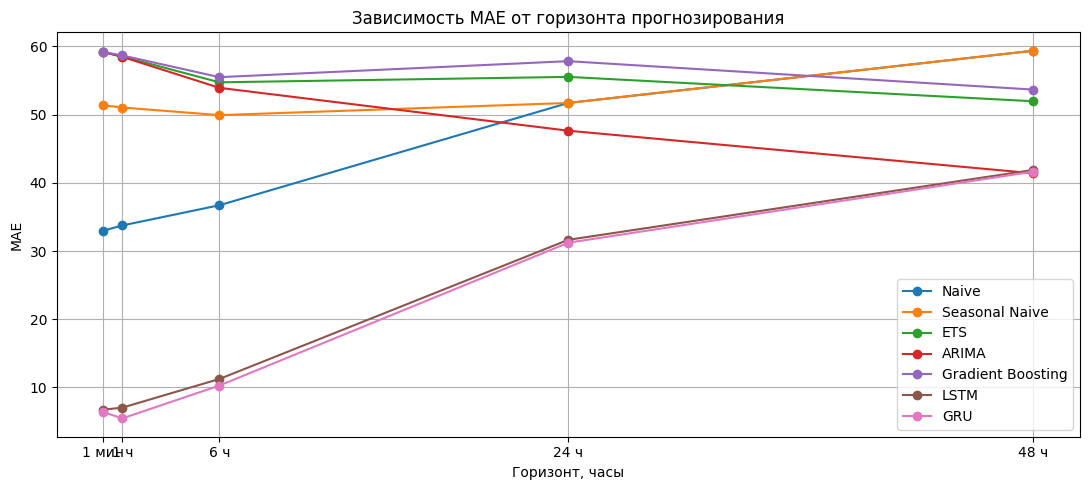

In [133]:
plt.figure(figsize=(11, 5))
for name, frame in lead_errors.items():
    plt.plot(frame["Lead (hours)"], frame["MAE"], marker="o", label=name)

plt.title("Зависимость MAE от горизонта прогнозирования")
plt.xlabel("Горизонт, часы")
plt.ylabel("MAE")
plt.xticks([1/60, 1, 6, 24, 48], ["1 мин", "1 ч", "6 ч", "24 ч", "48 ч"])
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 12. Walk-forward Backtesting

Две стратегии:

**Expanding** — обучающая история накапливается (start = 0).

**Rolling** — фиксированная длина (`rolling_size = 90 суток = 129 600 минут`). Выбрано 90 суток, а не 7 дней, потому что модели ETS и Gradient Boosting используют дневную историю с лагами до 30 дней: при окне 7 дней они физически не смогли бы обучиться. При этом 90 суток всё равно короче полной истории expanding (~1550 суток), так что стратегии дают **содержательно разные** результаты для этих моделей.

Наивные модели (Naive, Seasonal Naive) от длины истории не зависят — для них expanding и rolling дают идентичный прогноз. Это ожидаемое поведение, а не баг: в отчёте отмечено явно.

In [134]:
def walk_forward_backtest(series_values, series_index, model_fn,
                          initial_train, n_folds=3, horizon=HORIZON,
                          strategy="expanding", rolling_size=90 * 1440):
    folds = []
    for fold_number in range(n_folds):
        end = initial_train + fold_number * horizon
        if strategy == "expanding":
            start = 0
        elif strategy == "rolling":
            start = max(0, end - rolling_size)
        else:
            raise ValueError("strategy должна быть expanding или rolling")

        history = series_values[start:end]
        actual = series_values[end:end + horizon]
        if len(actual) != horizon:
            break
        if len(history) < SEASONAL_PERIOD:
            continue

        origin_ts = series_index[end]
        start_ts = series_index[start]

        prediction = model_fn(history, origin_ts, start_ts, horizon)
        folds.append({
            "fold": fold_number + 1,
            "history": history,
            "true": actual,
            "prediction": np.asarray(prediction),
            "origin_ts": origin_ts,
            "start_ts": start_ts,
        })
    return folds


# Обёртки под единый интерфейс walk_forward_backtest
def bt_naive(history, origin_ts, start_ts, horizon):
    return naive_forecast(history, horizon)


def bt_seasonal_naive(history, origin_ts, start_ts, horizon):
    return seasonal_naive_forecast(history, horizon)


def bt_ets(history, origin_ts, start_ts, horizon):
    daily = daily_clean.loc[
        (daily_clean.index >= start_ts.normalize())
        & (daily_clean.index < origin_ts.normalize())
    ].to_numpy(dtype=float)
    return ets_forecast(daily, horizon)


def bt_gb(history, origin_ts, start_ts, horizon):
    daily_series = daily_clean.loc[
        (daily_clean.index >= start_ts.normalize())
        & (daily_clean.index < origin_ts.normalize())
    ]
    return gb_forecast_from_series(daily_series, horizon)


backtest_models = {
    "Naive": bt_naive,
    "Seasonal Naive": bt_seasonal_naive,
    "ETS": bt_ets,
    "Gradient Boosting": bt_gb,
}

In [135]:
initial_train = test_slice.start
backtest_rows = []
backtest_folds = {}

for strategy in ["expanding", "rolling"]:
    for name, model_fn in backtest_models.items():
        folds = walk_forward_backtest(
            values, minute_series.index, model_fn,
            initial_train=initial_train,
            n_folds=3, strategy=strategy,
            rolling_size=90 * 1440,
        )
        backtest_folds[(strategy, name)] = folds
        for fold in folds:
            metrics = calculate_all_metrics(
                fold["true"], fold["prediction"], train_history_for_scale,
            )
            backtest_rows.append({
                "Strategy": strategy, "Model": name, "Fold": fold["fold"], **metrics,
            })

backtest_df = pd.DataFrame(backtest_rows)
if backtest_df.empty:
    raise RuntimeError("Backtesting не сформировал ни одного фолда")
display(backtest_df)

,Strategy,Model,Fold,MAE,RMSE,MASE,Pinball
0,expanding,Naive,1,23.189217,27.350151,0.775359,11.594609
1,expanding,Naive,2,31.901027,35.586399,1.066649,15.950513
2,expanding,Naive,3,8.710217,13.406536,0.291237,4.355108
3,expanding,Seasonal Naive,1,21.270782,25.042999,0.711214,10.635391
4,expanding,Seasonal Naive,2,40.804218,43.410063,1.364338,20.402109
5,expanding,Seasonal Naive,3,13.414249,16.346260,0.448522,6.707125
6,expanding,ETS,1,13.903221,15.776077,0.464871,6.951611
7,expanding,ETS,2,34.736155,37.431224,1.161445,17.368078
8,expanding,ETS,3,25.301803,28.306044,0.845996,12.650901
9,expanding,Gradient Boosting,1,19.642508,23.104128,0.656771,9.821254


,Strategy,Model,MAE,RMSE,MASE,Pinball
0,expanding,ETS,24.647060,27.171115,0.824104,12.323530
1,expanding,Gradient Boosting,27.740946,30.226700,0.927552,13.870473
2,expanding,Naive,21.266820,25.447695,0.711082,10.633410
3,expanding,Seasonal Naive,25.163083,28.266441,0.841358,12.581541
4,rolling,ETS,23.045561,25.842485,0.770556,11.522781
5,rolling,Gradient Boosting,24.968266,27.300487,0.834844,12.484133
6,rolling,Naive,21.266820,25.447695,0.711082,10.633410
7,rolling,Seasonal Naive,25.163083,28.266441,0.841358,12.581541


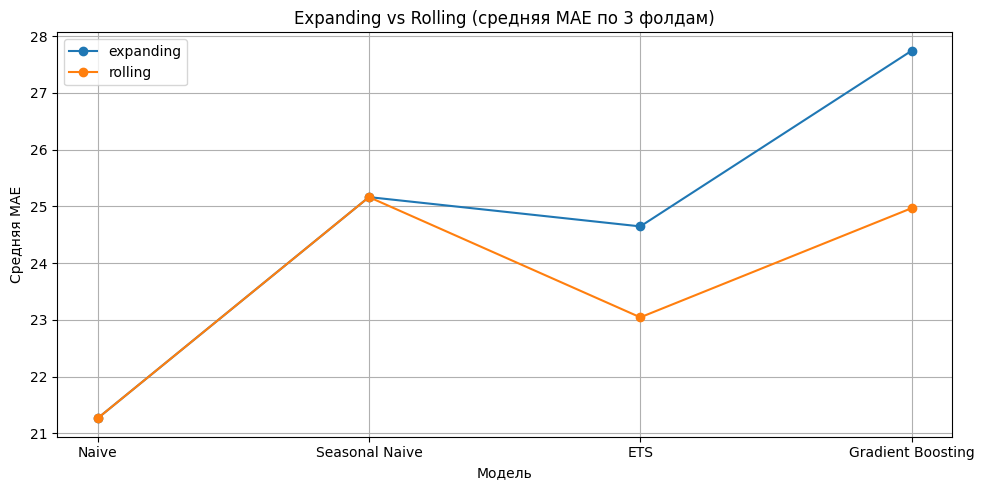

In [136]:
backtest_summary = (
    backtest_df.groupby(["Strategy", "Model"])[["MAE", "RMSE", "MASE", "Pinball"]]
    .mean().reset_index()
)
display(backtest_summary)

plt.figure(figsize=(10, 5))
models_order = ["Naive", "Seasonal Naive", "ETS", "Gradient Boosting"]
for strategy in ["expanding", "rolling"]:
    subset = backtest_summary[backtest_summary["Strategy"] == strategy].set_index("Model")
    subset = subset.reindex(models_order)
    plt.plot(subset.index, subset["MAE"], marker="o", label=strategy)
plt.title("Expanding vs Rolling (средняя MAE по 3 фолдам)")
plt.xlabel("Модель")
plt.ylabel("Средняя MAE")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [137]:
lines = ["### Вывод по walk-forward", ""]
pivot = backtest_summary.pivot(index="Model", columns="Strategy", values="MAE")
lines.append("| Модель | Expanding | Rolling | Δ (rolling − expanding) |")
lines.append("|---|---|---|---|")
for model in pivot.index:
    e = pivot.loc[model, "expanding"]
    r = pivot.loc[model, "rolling"]
    delta = r - e
    lines.append(f"| {model} | {e:.2f} | {r:.2f} | {delta:+.2f} |")

lines.append("")
lines.append(
    "**Замечание.** Naive и Seasonal Naive не зависят от длины истории — "
    "расхождение 0 ожидаемо. Содержательное сравнение стратегий обеспечивают "
    "ETS и Gradient Boosting: разница в MAE показывает, выигрывает ли модель "
    "от долгой истории или ей достаточно последних 90 суток."
)
display(Markdown("\n".join(lines)))

### Вывод по walk-forward

| Модель | Expanding | Rolling | Δ (rolling − expanding) |
|---|---|---|---|
| ETS | 24.65 | 23.05 | -1.60 |
| Gradient Boosting | 27.74 | 24.97 | -2.77 |
| Naive | 21.27 | 21.27 | +0.00 |
| Seasonal Naive | 25.16 | 25.16 | +0.00 |

**Замечание.** Naive и Seasonal Naive не зависят от длины истории — расхождение 0 ожидаемо. Содержательное сравнение стратегий обеспечивают ETS и Gradient Boosting: разница в MAE показывает, выигрывает ли модель от долгой истории или ей достаточно последних 90 суток.